# Day 5 · Choose what is worth shipping and deliver the project

Final day. We compare three single models with equal averaging, weighted averaging and stacking, ask whether the extra complexity earns its place, then export a reproducible calibrated model, `submission.csv`, a model card and a project bundle.

## 1. Setup

In [13]:
from pathlib import Path
import hashlib
import importlib.util
import os
import runpy
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request

RUN_STARTED = time.perf_counter()

COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
RAW_BASE = "https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template"


def running_in_colab():
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


IN_COLAB = running_in_colab()
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
ROOT.mkdir(parents=True, exist_ok=True)

setup_path = ROOT / "scripts" / "setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    for attempt in range(3):
        try:
            with urllib.request.urlopen(f"{RAW_BASE}/{COURSE_REVISION}/scripts/setup_colab.py", timeout=45) as reply:
                payload = reply.read(200_000)
            if hashlib.sha256(payload).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(payload)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry, or upload the unchanged project files.")
            time.sleep(attempt + 1)

prepare = runpy.run_path(str(setup_path))["prepare"]
try:
    environment = prepare(ROOT, COURSE_REVISION, MANIFEST_SHA256)
except RuntimeError as problem:
    if "already imported" not in str(problem):
        raise
    print("Installing the pinned package versions (one time, 1-2 minutes)...", flush=True)
    result = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "--quiet",
         "-r", str(ROOT / "requirements-colab.txt"), "-c", str(ROOT / "constraints.txt")],
        capture_output=True, text=True)
    if result.returncode:
        raise RuntimeError("Package installation failed:\n" + result.stderr[-3000:])
    print("Done. The runtime restarts by itself now (a 'session crashed' notice is expected).\n"
          "After it restarts, choose Runtime > Run all again.", flush=True)
    time.sleep(2)
    os.kill(os.getpid(), signal.SIGKILL)

FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified

PREVIOUS_SUPPORT = {
    "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7",
                                   "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
    "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d",
                                 "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12"),
    "scripts/day4_trust.py": ("4f6892d5c02923b5f8e3c78f4fcead73b043570f",
                              "7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c"),
}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"{RAW_BASE}/{revision}/{relative}", ROOT / relative, digest)

LAB_REVISION = "f486fc50dd9ac8403016facc58cf6a62beb4abf4"
SUPPORT_HASHES = {
    "scripts/day5_final.py": "71553cffc66f972e77d470a347cae40e4ca2802026535b48cb40168a59362b10",
    "scripts/day5_delivery.py": "eba5b5820550b44ccca2cf7f5d56a826c015de552e5db8d7e4c27a6e956ecd21",
    "scripts/inference.py": "abf1af0bca47bcd08e66f8218276773d39083e6f42f42caeea5d8b2db70c0a6a",
    "scripts/replay_final.py": "adcb2e40aff819439068cd7a2aca9fcb6f8632b0c551a9d04f7bd63efc8506fb",
    "scripts/rebuild_final.py": "ac18b78160dbc33b720f3e1038667110760832c095e23c1ea7f909d4c5760dfd",
    "data/tamweel_oof_matrix.csv": "f8c9429c7eed015d53978fba93b4b32ed3266fa15b63471b03881ab5c09804b5",
    "data/day5_oof_example.json": "9edcb173ab5aa504af3ef79c4f3371cd285fa4b171be1bcc6dd9da1d7fb0394d",
    "presentation/FINAL_PRESENTATION_TEMPLATE.md": "8d3df570727b18db097c9c78ed518ac09bd8766dbdba2817ae8883e43ed5de39",
    "presentation/FINAL_PRESENTATION_GUIDE.md": "1d24149ef2e56df0a6c44e000157135904b8ba3d252445e4367a6de547c87b19",
}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"{RAW_BASE}/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 5 setup verified")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.13.18 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.
Day 5 setup verified


## 2. Reserve calibration and respect label availability

The target is a default within 90 days of applying. July to September 2024 is reserved for calibration only, and its customers are removed from the fit-and-selection pool. The pool holds only applications whose outcomes matured before 1 July 2024.

Comparison folds are 2023Q1, 2023Q3 and 2024Q1. In each outer fold the training period ends early enough for the 90-day outcome to mature, and validation customers are removed from training. A second forward split inside the outer training rows learns the averaging weights and the logistic stacker, so no meta-model ever sees in-sample base predictions. This is development evidence, not an untouched final test, and challenge labels do not exist.

In [14]:
import json
import platform
import zipfile
from dataclasses import asdict
from hashlib import sha256

import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink

from data_checks import validate_frame
from day5_final import (BASE, ENSEMBLES, TARGET, FinalConfig, EnsembleBudgetExpired, split_final_roles,
                        nested_comparison, load_example, worth_it, selected_oof, fit_final, export_model,
                        predict_final, transport_threshold, apply_batch_policy, write_json)
from day3_decision import CostPolicy, threshold_sweep, select_threshold, region_audit, period_audit
from day4_trust import probability_metrics, reliability_table, map_probability
from day5_delivery import (RESPONSES, reflection_check, import_daily_evidence, evidence_status,
                           validate_submission, replay_submission, create_bundle, verify_bundle)

STARTED = time.perf_counter()
contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train = pd.read_csv(ROOT / "data/tamweel_train.csv")
challenge = pd.read_csv(ROOT / "data/tamweel_challenge.csv")
validate_frame(train, contract, "train")
validate_frame(challenge, contract, "challenge")
assert not set(train.customer_id) & set(challenge.customer_id)

FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE
config = FinalConfig() if FAST_MODE else FinalConfig(trees=160, seconds=240)
USE_OOF_EXAMPLE = False
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
pool, calibration, roles = split_final_roles(train)

ARTIFACTS, REPORTS, SUBMISSION = ROOT / "artifacts", ROOT / "reports", ROOT / "submission"
for folder in (ARTIFACTS, REPORTS, SUBMISSION):
    folder.mkdir(exist_ok=True)

BLUE, ORANGE, GREEN, GREY, SAND = "#2667A0", "#BA5A17", "#18816A", "#777777", "#D3D9DE"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.2})
SAVE = {"dpi": 160, "bbox_inches": "tight"}

display(pd.DataFrame([{
    "role": name, "rows": len(frame), "customers": frame.customer_id.nunique(),
    "positives": int(frame[TARGET].sum()), "first_date": frame.application_date.min(),
    "last_date": frame.application_date.max()}
    for name, frame in [("fit + selection", pool), ("calibration only", calibration)]]))
print("Excluded rows:", int(roles.role.str.startswith("excluded").sum()))

,role,rows,customers,positives,first_date,last_date
0,fit + selection,6576,3931,537,2022-01-01,2024-04-01
1,calibration only,836,788,78,2024-07-01,2024-09-30


Excluded rows: 2588


## 3. Build nested forward OOF without leakage

Unweighted LightGBM, XGBoost and Logistic Regression are compared; error cost is handled later by the threshold. Imputation and scaling are learned inside training only. The weighted average searches a small grid of non-negative weights that sum to one, on inner OOF only, and the logistic stacker learns from the same three inner-OOF columns. Base learners are then refit on the outer training data and all six candidates are scored on the outer validation period. Weights and coefficients may differ by fold, because what we compare is the learning procedure. If the CPU budget runs out, a labelled example may appear instead; it exports no final model or submission.

In [15]:
try:
    if USE_OOF_EXAMPLE:
        raise EnsembleBudgetExpired("Educational OOF example requested.")
    oof, fold_scores, oof_provenance = nested_comparison(pool, contract, config)
except EnsembleBudgetExpired:
    oof, fold_scores, oof_provenance = load_example(ROOT / "data/tamweel_oof_matrix.csv",
                                                    ROOT / "data/day5_oof_example.json",
                                                    pool, config, assessment_mode=ASSESSMENT_MODE)
SOURCE = oof.source.iloc[0]
if SOURCE != "LIVE":
    print("EDUCATIONAL_EXAMPLE: for discussion only, no final model or submission.")
display(oof[["application_id", "fold", *BASE, *ENSEMBLES]].head().round(4))
print(f"{SOURCE}: {len(oof):,} OOF rows across three forward periods; warm-up rows have no outer OOF.")

,application_id,fold,LightGBM,XGBoost,Logistic,Equal,Weighted,Stack
0,TR-001160,1,0.0321,0.0444,0.0467,0.0410,0.0461,0.0684
1,TR-003137,1,0.1149,0.1798,0.1547,0.1498,0.1610,0.1085
2,TR-004529,1,0.0457,0.0854,0.0887,0.0733,0.0879,0.0796
3,TR-004666,1,0.0123,0.0150,0.0062,0.0112,0.0084,0.0593
4,TR-008372,1,0.0373,0.0538,0.0336,0.0416,0.0387,0.0674


LIVE: 2,155 OOF rows across three forward periods; warm-up rows have no outer OOF.


## 4. Inspect prediction and residual diversity

The left heatmap shows how the three base models' OOF probabilities move together; the right one shows the residuals `p - y` on the same requests. Residuals share the target, so they can stay highly correlated. Correlation is descriptive, and low correlation alone neither proves an ensemble gain nor justifies adding a weak model.

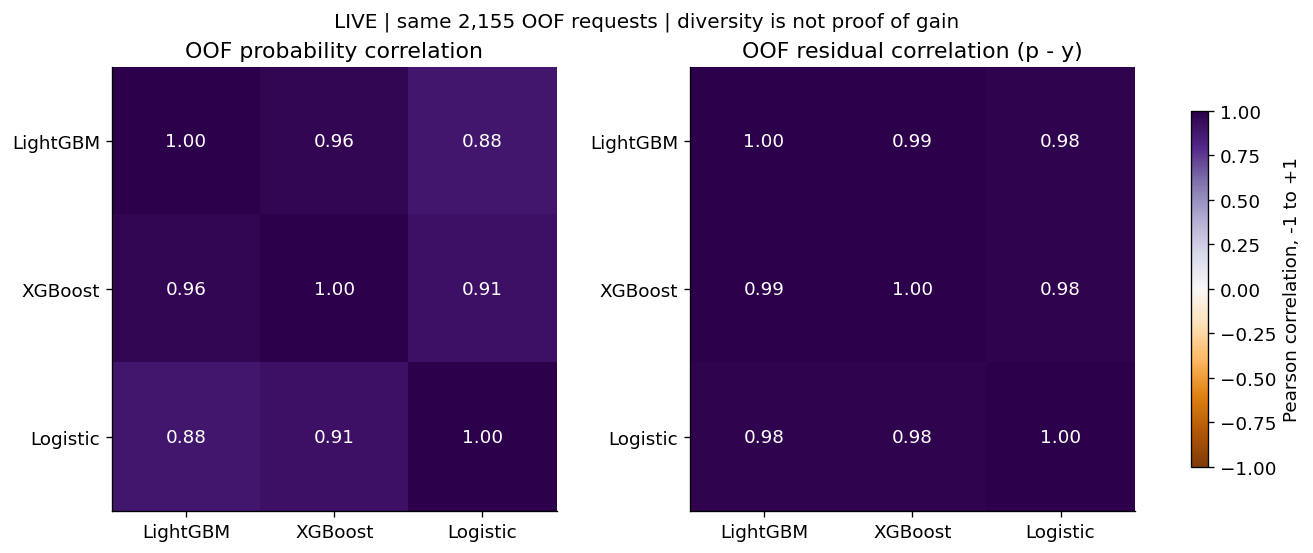

In [16]:
correlation = oof[list(BASE)].corr()
residual_correlation = oof[list(BASE)].sub(oof[TARGET], axis=0).corr()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, table, title in [(axes[0], correlation, "OOF probability correlation"),
                         (axes[1], residual_correlation, "OOF residual correlation (p - y)")]:
    image = ax.imshow(table, vmin=-1, vmax=1, cmap="PuOr")
    ax.grid(False)
    ax.set_xticks(range(3), BASE)
    ax.set_yticks(range(3), BASE)
    ax.set_title(title)
    for i in range(3):
        for j in range(3):
            value = table.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if abs(value) > .6 else "#222222")
fig.colorbar(image, ax=axes, shrink=.8, label="Pearson correlation, -1 to +1")
fig.suptitle(f"{SOURCE} | same {len(oof):,} OOF requests | diversity is not proof of gain", fontsize=12)
fig.savefig(ARTIFACTS / "day5_diversity.png", **SAVE)
plt.show()

## 5. Apply the worth-it gate

The best single model is the one with the highest mean Average Precision over the three forward folds. An ensemble is accepted only if its AP gain is larger than that single model's fold standard deviation, its Brier does not worsen by more than 0.005 and its ECE by more than 0.01. These are fixed teaching rules, not a significance test: the standard deviation comes from only three overlapping periods. If several ensembles pass, the simplest wins (equal, then weighted, then stack), and an ensemble is never forced to win.

,candidate,mean_ap,fold_sd,mean_brier,mean_ece,lift_vs_single,passes_gate
0,LightGBM,0.3455,0.0435,0.0661,0.0231,-0.0462,False
1,XGBoost,0.3526,0.0290,0.0657,0.0228,-0.0390,False
2,Logistic,0.3917,0.0298,0.0633,0.0188,0.0000,False
3,Equal,0.3717,0.0326,0.0643,0.0204,-0.0200,False
4,Weighted,0.3894,0.0291,0.0633,0.0177,-0.0022,False
5,Stack,0.3831,0.0295,0.0660,0.0311,-0.0085,False


KEEP SINGLE -> Logistic


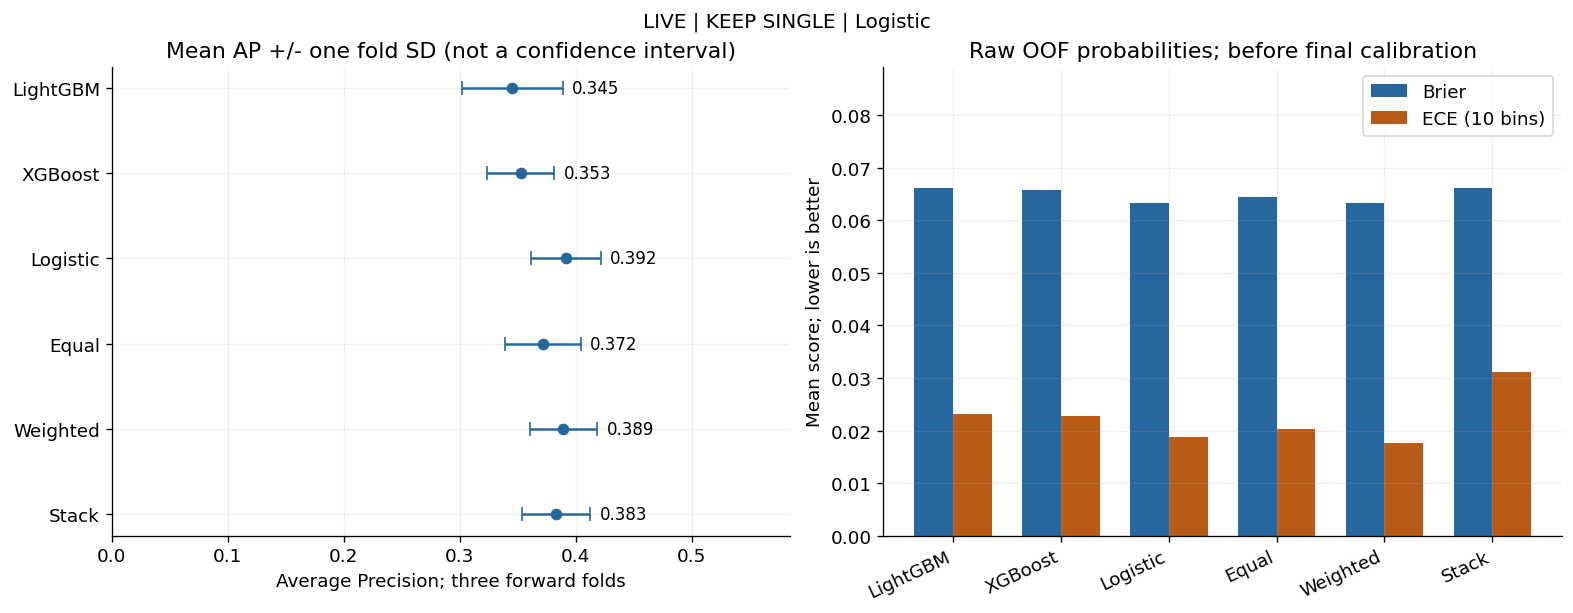

In [17]:
comparison, gate = worth_it(fold_scores, config)
display(comparison.round(4))
print(gate["decision"], "->", gate["chosen"])

order = list(BASE + ENSEMBLES)
fig, (ax_ap, ax_cal) = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for i, name in enumerate(order):
    row = comparison.set_index("candidate").loc[name]
    ax_ap.errorbar(row.mean_ap, i, xerr=row.fold_sd, fmt="o", color=BLUE, capsize=4)
    ax_ap.text(row.mean_ap + row.fold_sd + .008, i, f"{row.mean_ap:.3f}", va="center", fontsize=10)
ax_ap.set_yticks(range(6), order)
ax_ap.invert_yaxis()
ax_ap.set_xlim(0, min(1, comparison.mean_ap.max() + comparison.fold_sd.max() + .15))
ax_ap.set_title("Mean AP +/- one fold SD (not a confidence interval)")
ax_ap.set_xlabel("Average Precision; three forward folds")

x = np.arange(6)
ax_cal.bar(x - .18, comparison.mean_brier, .36, label="Brier", color=BLUE)
ax_cal.bar(x + .18, comparison.mean_ece, .36, label="ECE (10 bins)", color=ORANGE)
ax_cal.set_xticks(x, order, rotation=25, ha="right")
ax_cal.set_ylabel("Mean score; lower is better")
ax_cal.set_title("Raw OOF probabilities; before final calibration")
ax_cal.legend()
ax_cal.set_ylim(0, max(comparison.mean_brier.max(), comparison.mean_ece.max()) * 1.35)
fig.suptitle(f"{SOURCE} | {gate['decision']} | {gate['chosen']}", fontsize=12)
fig.savefig(ARTIFACTS / "day5_ensemble_comparison.png", **SAVE)
plt.show()

## 6. Freeze the OOF decision policy

Every distinct OOF score of the chosen model is tried as a threshold, looking for the lowest teaching loss `10 x FN + FP` that keeps every fold and the total within 12% capacity. Equal scores stay in one block. Loss units are fictional (not riyals, fees or grade deductions). The regional table is a descriptive OOF diagnostic with denominators and positive counts, not a fairness certificate, and challenge FPR cannot be computed without labels. The sensitivity table changes only the FN cost while the model, threshold and decisions stay fixed.

,threshold,tp,fp,fn,tn,flagged,flag_fraction,recall,precision,false_positive_rate,accuracy,loss_units,loss_units_per_10000,capacity_feasible,max_period_flag_fraction,rows,source
0,0.1689,84,161,95,1815,245,0.1137,0.4693,0.3429,0.0815,0.8812,1111.0,5155.4524,True,0.1175,2155,LIVE


,region,rows,negatives,positives,flagged,false_positives,true_positives,false_positive_rate,recall,low_negative_support,source
0,central,537,489,48,63,39,24,0.0798,0.5000,False,LIVE
1,western,533,486,47,71,50,21,0.1029,0.4468,False,LIVE
2,eastern,542,507,35,48,32,16,0.0631,0.4571,False,LIVE
3,other,543,494,49,63,40,23,0.0810,0.4694,False,LIVE


,false_negative_cost,false_positive_cost,fixed_threshold,loss_units
0,8,1,0.168922,921
1,10,1,0.168922,1111
2,12,1,0.168922,1301


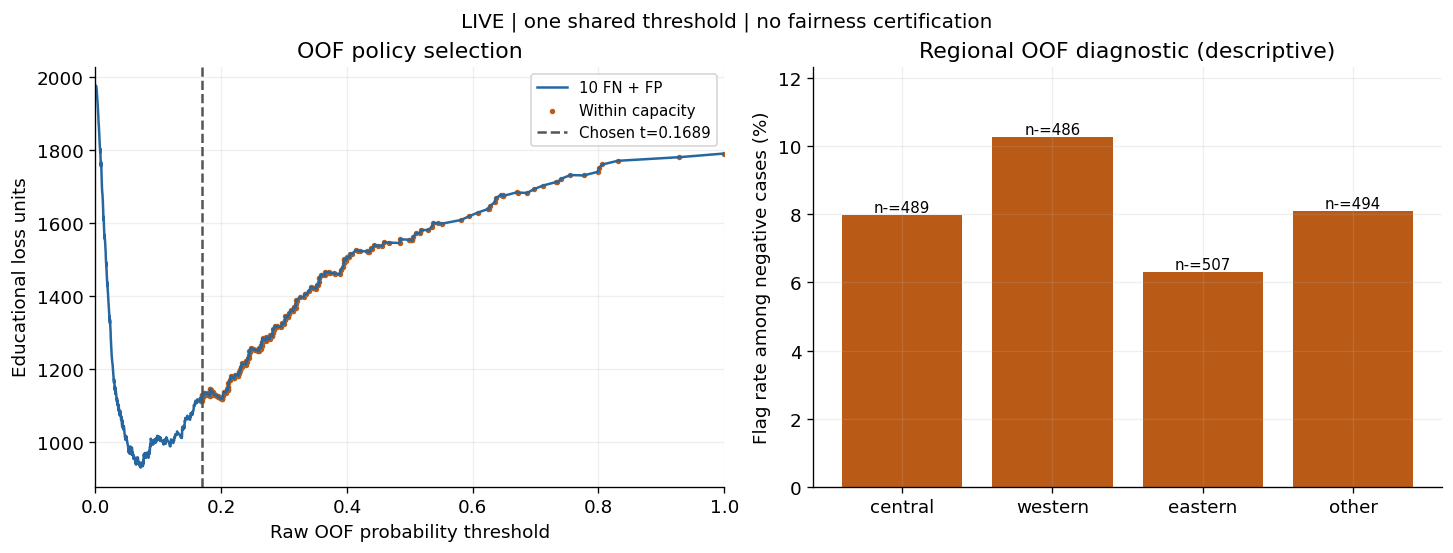

In [18]:
policy = CostPolicy()
selected = selected_oof(oof, gate["chosen"])
sweep = threshold_sweep(selected, policy)
threshold_choice = select_threshold(sweep)
raw_threshold = float(threshold_choice["threshold"])
regional, regional_summary = region_audit(selected, raw_threshold)
period_capacity = period_audit(selected, raw_threshold, policy)
sensitivity = pd.DataFrame([{
    "false_negative_cost": cost, "false_positive_cost": 1, "fixed_threshold": raw_threshold,
    "loss_units": cost * int(threshold_choice["fn"]) + int(threshold_choice["fp"])} for cost in (8, 10, 12)])

display(pd.DataFrame([threshold_choice]).round(4))
display(regional.round(4))
display(sensitivity)

fig, (ax_loss, ax_reg) = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
ax_loss.plot(sweep.threshold, sweep.loss_units, color=BLUE, label="10 FN + FP")
feasible = sweep[sweep.capacity_feasible]
ax_loss.scatter(feasible.threshold, feasible.loss_units, s=5, color=ORANGE, label="Within capacity")
ax_loss.axvline(raw_threshold, color="#555555", ls="--", label=f"Chosen t={raw_threshold:.4f}")
ax_loss.set(xlim=(0, 1), xlabel="Raw OOF probability threshold", ylabel="Educational loss units",
            title="OOF policy selection")
ax_loss.legend(fontsize=9)
ax_reg.bar(regional.region, regional.false_positive_rate * 100, color=ORANGE)
ax_reg.set(ylabel="Flag rate among negative cases (%)", title="Regional OOF diagnostic (descriptive)")
for i, row in regional.iterrows():
    ax_reg.text(i, row.false_positive_rate * 100, f"n-={row.negatives}", ha="center", va="bottom", fontsize=9)
ax_reg.margins(y=.2)
fig.suptitle(f"{SOURCE} | one shared threshold | no fairness certification", fontsize=12)
fig.savefig(ARTIFACTS / "day5_policy_regions.png", **SAVE)
plt.show()

## 7. Refit the chosen procedure and freeze calibration

The chosen learning procedure is refit on the eligible pool, and one sigmoid mapping is learned on the reserved calibration period only. The estimator is not retrained afterwards, because an old calibrator and threshold would no longer match it. The OOF threshold is carried to the calibrated scale through the monotone mapping. The reliability figure is a **calibration-fit diagnostic** on the very rows that taught the calibrator, so it is not independent evidence. Moving a threshold from OOF models to a refit model can change flag volume, which is why capacity is applied to the whole batch later. Day 4 SHAP explanations belong to the Day 4 model and are not automatically valid for a different final model.

,rows,positives,prevalence,roc_auc,average_precision,brier,log_loss,ece,bins,binning
raw_fit_diagnostic,836,78,0.093301,0.789037,0.287803,0.076473,0.266489,0.021121,10,"fixed width, [lower, upper); final bin includes 1"
sigmoid_fit_diagnostic,836,78,0.093301,0.789037,0.287803,0.078058,0.277296,0.034871,10,"fixed width, [lower, upper); final bin includes 1"


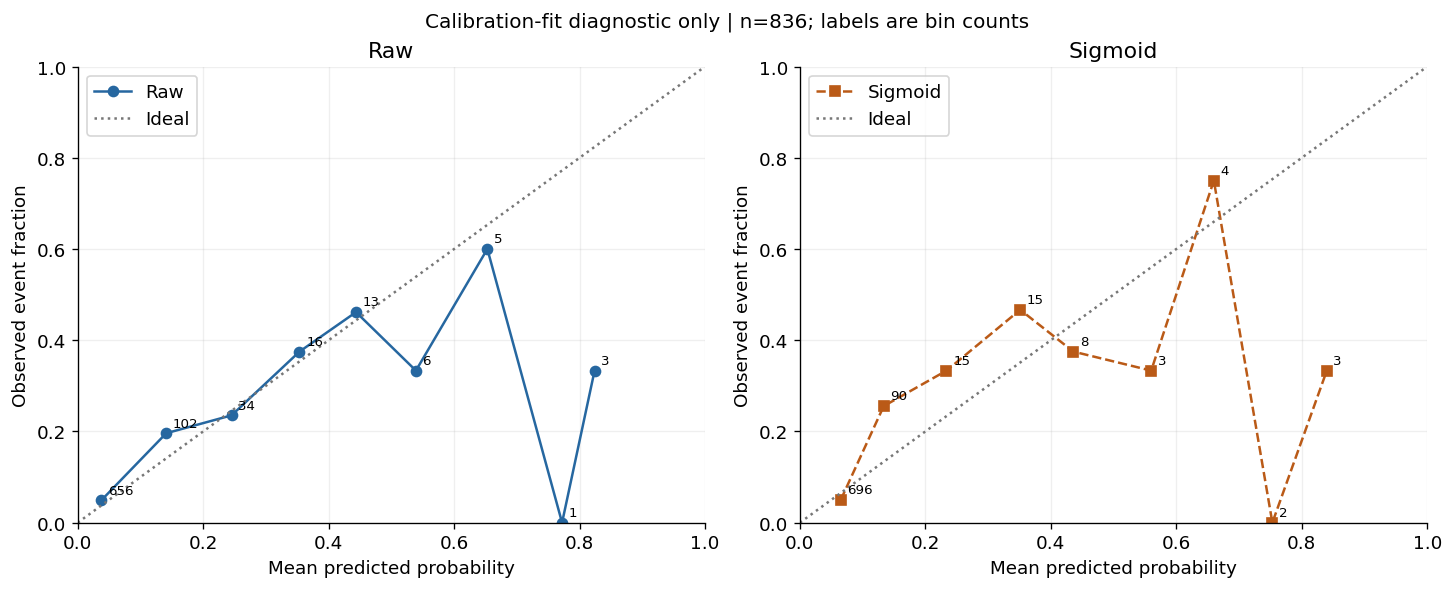

Final model and sigmoid frozen; transported threshold: 0.12225843144286948


In [19]:
if SOURCE == "LIVE":
    final_model, mapping, calibration_predictions, final_provenance = fit_final(
        pool, calibration, contract, gate["chosen"], config)
    calibrated_threshold = transport_threshold(raw_threshold, mapping)
    final_model_manifest = export_model(final_model, mapping, contract, ARTIFACTS / "final_model")
    calibration_diagnostics = {
        name: probability_metrics(calibration_predictions[TARGET], calibration_predictions[column])
        for name, column in [("raw_fit_diagnostic", "raw_probability"), ("sigmoid_fit_diagnostic", "probability")]}
    bins = pd.concat([
        reliability_table(calibration_predictions[TARGET], calibration_predictions[column]).assign(series=name)
        for name, column in [("Raw", "raw_probability"), ("Sigmoid", "probability")]], ignore_index=True)
    display(pd.DataFrame(calibration_diagnostics).T.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
    for ax, name, style, color in [(axes[0], "Raw", "o-", BLUE), (axes[1], "Sigmoid", "s--", ORANGE)]:
        table = bins[(bins.series == name) & (bins["count"] > 0)]
        ax.plot(table.mean_probability, table.observed_rate, style, label=name, color=color)
        for row in table.itertuples():
            ax.annotate(str(row.count),
                        (row.mean_probability, row.observed_rate), xytext=(4, 4),
                        textcoords="offset points", fontsize=8)
        ax.plot([0, 1], [0, 1], ":", color=GREY, label="Ideal")
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability",
               ylabel="Observed event fraction", title=name)
        ax.legend()
    fig.suptitle(f"Calibration-fit diagnostic only | n={len(calibration)}; labels are bin counts", fontsize=12)
    fig.savefig(ARTIFACTS / "day5_calibration_fit.png", **SAVE)
    plt.show()
    print("Final model and sigmoid frozen; transported threshold:", calibrated_threshold)
else:
    print("EXAMPLE_ONLY_NOT_SUBMITTABLE: final fitting, inference and submission are skipped.")

## 8. Score every challenge request and apply capacity once

`inference.predict` returns each application ID with its calibrated probability, in request order. Probabilities may be computed in chunks, but all chunks are joined before the full-batch policy is applied once. Candidates are the requests above the transported threshold; if they exceed 12% of the 2,500-request batch, the highest probabilities are kept up to 300. An equal-score block is never split by identifier: if the whole boundary block does not fit, it is dropped and capacity stays partly unused. `decision = 1` is a simulated review flag and `decision = 0` is not an approval or a safety guarantee. Challenge AP, loss and FPR are not computed because labels do not exist.

,application_id,probability,decision
0,CH-000278,0.114104,0
1,CH-001412,0.120922,0
2,CH-001444,0.055587,0
3,CH-002174,0.053426,0
4,CH-002260,0.077174,0


,rows,capacity,threshold_eligible,flagged,removed_by_cap,boundary_score,within_capacity,tie_policy,batch_policy
0,2500,300,330,300,30,0.129908,True,retain entire equal-score blocks; drop boundar...,"threshold first, then probability-descending f..."


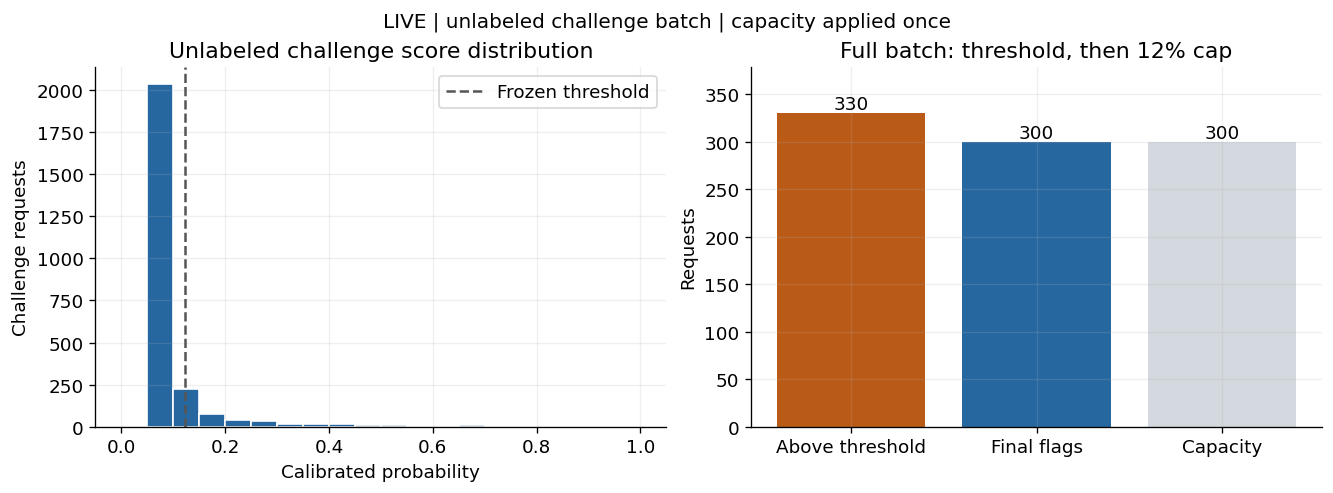

In [20]:
if SOURCE == "LIVE":
    from inference import predict
    predictions = predict(challenge, ARTIFACTS / "final_model")
    submission, batch_audit = apply_batch_policy(predictions, calibrated_threshold, policy)
    validate_submission(submission, challenge, calibrated_threshold, policy)
    expected = map_probability(
        final_model.predict_proba(challenge[[f["name"] for f in contract["features"]]])[:, 1], mapping)
    assert np.allclose(predictions.probability, expected, rtol=0, atol=1e-12)
    display(submission.head())
    display(pd.DataFrame([batch_audit]))

    fig, (ax_dist, ax_cap) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    ax_dist.hist(predictions.probability, bins=np.linspace(0, 1, 21), color=BLUE, edgecolor="white")
    ax_dist.axvline(calibrated_threshold, color="#555555", ls="--", label="Frozen threshold")
    ax_dist.set(xlabel="Calibrated probability", ylabel="Challenge requests",
                title="Unlabeled challenge score distribution")
    ax_dist.legend()
    counts = [batch_audit["threshold_eligible"], batch_audit["flagged"], batch_audit["capacity"]]
    ax_cap.bar(["Above threshold", "Final flags", "Capacity"], counts, color=[ORANGE, BLUE, SAND])
    ax_cap.set(ylabel="Requests", title="Full batch: threshold, then 12% cap")
    for i, n in enumerate(counts):
        ax_cap.text(i, n, str(n), ha="center", va="bottom")
    ax_cap.margins(y=.15)
    fig.suptitle("LIVE | unlabeled challenge batch | capacity applied once", fontsize=12)
    fig.savefig(ARTIFACTS / "day5_challenge_capacity.png", **SAVE)
    plt.show()
else:
    print("No challenge predictions are produced from the educational example.")

## 9. Write the decision and assemble your evidence

In [21]:
responses = {
    "ensemble_reason": (
        "I kept a single model, Logistic Regression. It had the best mean Average Precision across the three "
        "forward folds (0.392, fold SD 0.030), ahead of XGBoost (0.353) and LightGBM (0.346). No ensemble beat "
        "it: equal averaging scored 0.372 (-0.020), weighted averaging 0.389 (-0.002) and stacking 0.383 "
        "(-0.009), so none came close to the required gain of more than 0.030. Brier (0.0633 vs 0.0633) and ECE "
        "(0.0188 vs 0.0177) were also no better in a way that would justify the extra complexity. Gate result: "
        "KEEP SINGLE."),
    "validation_limits": (
        "The evidence is nested forward OOF: folds 2023Q1, 2023Q3 and 2024Q1, training far enough in the past "
        "for 90-day outcomes to mature, validation customers removed from training, and ensemble weights and "
        "the stacker learned on inner OOF only. The limits are that three periods overlap in their training "
        "history, so the fold SD (0.030) is descriptive and not a confidence interval, that the AP gaps between "
        "candidates are small, and that the same training data was used earlier in the course, so this is not "
        "an untouched final test."),
    "calibration_limits": (
        "The sigmoid was learned on a reserved period (July to September 2024, 836 rows, 78 positives) kept out "
        "of the fit pool, but its diagnostics are scored on those same rows, so they are fit diagnostics, not "
        "independent evidence. On them the sigmoid left ranking unchanged (AP 0.288, ROC-AUC 0.789) and did not "
        "improve calibration (Brier 0.0765 to 0.0781, ECE 0.0211 to 0.0349), which suggests the unweighted "
        "logistic scores were already reasonably calibrated. With only 78 positives the estimate is noisy, and "
        "no challenge labels exist to test it."),
    "capacity_fairness": (
        "Capacity was applied once to the whole 2,500-request batch: 330 requests were above the transported "
        "threshold (0.1223), the 300-request cap kept 300 and removed 30 (boundary score 0.1299), and no "
        "equal-score block was split. The regional OOF flag rate among negatives ranges from 6.3% (eastern) to "
        "10.3% (western), a gap of 3.98 percentage points, with 486 to 507 negatives per region. This is a "
        "descriptive diagnostic with no confidence interval and is not a fairness certificate; challenge FPR "
        "cannot be computed without labels."),
    "explanation_scope": (
        "The Day 4 explanations belong to the class-weighted LightGBM of Day 4. The final model is an "
        "unweighted Logistic Regression with a sigmoid calibrator, so those SHAP values and reason codes do not "
        "transfer to it. For the final model I would need to recheck its own coefficients or SHAP values, the "
        "calibration, and the review zone against the 12% capacity before explaining any individual decision."),
    "intended_use": (
        "This is a fictional training exercise on synthetic data. The flags simulate sending a request to "
        "review. It must not be used for real financing, to approve or reject an applicant, or as evidence "
        "about real people or regions."),
    "monitoring_plan": (
        "Track feature and score distributions against the training data for drift; the share of requests "
        "flagged per period against the 12% capacity; calibration (Brier, ECE and reliability) on each newly "
        "labelled period, recalibrating or retraining when it drifts; and the regional flag rate and recall. "
        "Because the transported threshold can change flag volume after refitting, capacity must be checked on "
        "every new batch before use."),
    "executive_summary_ar": (
        "اخترنا نموذج Logistic Regression منفرداً لأنه حقق أعلى متوسط Average Precision (0.392) عبر الطيات الأمامية "
        "الثلاث، ولم يتجاوزه أي تجميع بالقدر المطلوب (أكثر من 0.030). عُيّرت الاحتمالات بتحويل sigmoid، وطُبقت "
        "سعة 12% مرة واحدة على دفعة التحدي (300 إشارة من 2,500 طلب). البيانات اصطناعية والنتائج للتدريب فقط."),
    "executive_summary_en": (
        "We chose a single Logistic Regression because it had the best mean Average Precision (0.392) across "
        "three forward folds, and no ensemble beat it by more than the 0.030 fold SD. Probabilities were "
        "calibrated with a sigmoid and the 12% capacity was applied once to the challenge batch (300 flags of "
        "2,500 requests). The data are synthetic and the results are for training only."),
}
checkpoint = reflection_check(responses, SOURCE)
print(checkpoint["status"], "| Missing:", checkpoint["missing"])
print("Upload your previous daily ZIPs here if available:", ROOT)

READY_FOR_REVIEW | Missing: []
Upload your previous daily ZIPs here if available: /content/tamweel


## 10. Export and verify the project bundle

In [22]:
def clean_json(value):
    if isinstance(value, dict):
        return {str(k): clean_json(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [clean_json(v) for v in value]
    if isinstance(value, np.generic):
        return clean_json(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


tables = {
    "day5_roles.csv": roles, "day5_oof_predictions.csv": oof, "day5_fold_scores.csv": fold_scores,
    "ensemble_comparison.csv": comparison, "day5_threshold_sweep.csv": sweep,
    "day5_region_audit.csv": regional, "day5_period_capacity.csv": period_capacity,
    "day5_cost_sensitivity.csv": sensitivity}
for name, table in tables.items():
    table.to_csv(ARTIFACTS / name, index=False)
correlation.to_csv(ARTIFACTS / "day5_probability_correlation.csv")
residual_correlation.to_csv(ARTIFACTS / "day5_residual_correlation.csv")

run = {
    "technical_status": "TECHNICAL_READY" if SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE",
    "source": SOURCE, "chosen": gate["chosen"], "decision": gate["decision"], "config": asdict(config),
    "learner_status": checkpoint["status"], "lab_revision": LAB_REVISION, "support_hashes": SUPPORT_HASHES,
    "previous_support": PREVIOUS_SUPPORT, "data_revision": COURSE_REVISION,
    "python": platform.python_version(), "elapsed_seconds": round(time.perf_counter() - STARTED, 2),
    "challenge_labels_used": False, "automatic_grade": None}
json_payloads = {
    "day5_run.json": run, "day5_reflection.json": {"responses": responses, "checkpoint": checkpoint},
    "day5_oof_provenance.json": oof_provenance, "day5_ensemble_gate.json": gate}
for name, payload in json_payloads.items():
    write_json(ARTIFACTS / name, clean_json(payload))

if SOURCE != "LIVE":
    example_zip = ROOT / "day5_example_analysis.zip"
    with zipfile.ZipFile(example_zip, "w", zipfile.ZIP_DEFLATED) as archive:
        for name in [*tables, "day5_run.json", "day5_ensemble_gate.json", "day5_diversity.png",
                     "day5_ensemble_comparison.png", "day5_policy_regions.png"]:
            archive.write(ARTIFACTS / name, name)
    print("EXAMPLE_ONLY_NOT_SUBMITTABLE: comparison only; no model, submission or project bundle exported.")
    display(FileLink(str(example_zip)))
else:
    submission.to_csv(SUBMISSION / "submission.csv", index=False)
    calibration_predictions.to_csv(ARTIFACTS / "day5_calibration_predictions.csv", index=False)
    bins.to_csv(ARTIFACTS / "day5_calibration_fit_bins.csv", index=False)
    final_policy = {"raw_oof_threshold": raw_threshold, "calibrated_threshold": calibrated_threshold,
                    "cost_policy": asdict(policy), "mapping": mapping, "batch_audit": batch_audit}
    final_metrics = {
        "gate": gate, "oof_threshold_selection": threshold_choice, "regional_oof": regional_summary,
        "calibration_fit_diagnostics": calibration_diagnostics, "challenge_metrics": None,
        "challenge_metrics_reason": "Labels unavailable; no AP/loss/FPR claimed.", "challenge_batch": batch_audit}
    write_json(ARTIFACTS / "final_policy.json", clean_json(final_policy))
    write_json(ARTIFACTS / "final_metrics.json", clean_json(final_metrics))
    write_json(ARTIFACTS / "day5_final_provenance.json", clean_json(final_provenance))

    reproduced = replay_submission(ROOT)
    assert np.allclose(reproduced.probability, submission.probability, rtol=0, atol=1e-12)
    assert np.array_equal(reproduced.decision, submission.decision)

    answer = lambda key: responses[key].strip() or "[Write your interpretation from your results here]"
    NL = chr(10)
    card = f"""# Model card | Tamweel Lite

## Status
{checkpoint['status']}. The quality of the reasoning still needs human review; this is not an automatic grade.

## Purpose and use
{answer('intended_use')}

Tamweel Lite data is synthetic; the target is a default event within 90 days of the application. The model uses the 22 features available at application time, with no identifiers, dates or target in the inputs. Training use only: no real financing decisions.

## Data and validation
Fit-and-selection pool: {len(pool)} applications. Calibration period: {len(calibration)} applications with {int(calibration[TARGET].sum())} positives, with its customers held out. Labels must be 90 days mature, and the nested forward OOF keeps customers separate at both levels. Comparison folds are 2023Q1, 2023Q3 and 2024Q1. Rows whose outcomes would not yet have matured are left out, and the most recent training data is not used automatically.

{answer('validation_limits')}

## Model selection
{gate['decision']} / {gate['chosen']}. Reference fold SD of AP: {gate['fold_sd_reference']:.6f}. Full numbers are in `artifacts/ensemble_comparison.csv` and `day5_fold_scores.csv`.

{answer('ensemble_reason')}

## Calibration
A sigmoid was learned on the reserved calibration sample. The plot and metrics are fit diagnostics on the rows that taught the calibrator, not independent evidence. No improvement is claimed for the unlabeled challenge set.

{answer('calibration_limits')}

## Policy, capacity and regions
Loss 10 FN + FP. Raw OOF threshold {raw_threshold:.17g}, transported threshold {calibrated_threshold:.17g}. Batch capacity {batch_audit['capacity']}; threshold candidates {batch_audit['threshold_eligible']}; final flags {batch_audit['flagged']}. Equal-score blocks are never split. 1 = a simulated review flag, 0 = flag not raised.

{answer('capacity_fairness')}

## Explanation scope
Day 4 explanations belong to the Day 4 model and are not attributed automatically to this version. A change of model, features or calibration requires rechecking them.

{answer('explanation_scope')}

## Monitoring and limitations
{answer('monitoring_plan')}

OOF evidence is used for selection, and three periods are not a significance test. The threshold's capacity effect can change when moved to a refitted model. There are no challenge labels, so no performance or fairness claim is made for it. The data does not represent real people or regions.

## Reproducibility
seed={config.seed}; trees={config.trees}; free CPU. Package versions are in `artifacts/environment.json` and source hashes in `artifacts/day5_run.json`. The model is in `artifacts/final_model`; `inference.predict` returns an ID and a probability, and the policy is applied after the whole batch is collected. `replay_final` reproduces the saved predictions and `rebuild_final` retrains from data. Do not retrain the model after the calibrator is frozen.

## Submission ownership
Complete the earlier days' evidence and the presentation, save the executed notebook, then record your repository SHA and tag in the private submission channel. The course support revision {LAB_REVISION} is not your submission SHA.
"""
    (REPORTS / "MODEL_CARD.md").write_text(card, encoding="utf-8")
    decision_text = (f"# Ensemble decision{NL}{NL}{gate['decision']}: {gate['chosen']}{NL}{NL}"
                     f"{answer('ensemble_reason')}{NL}{NL}{answer('validation_limits')}{NL}{NL}"
                     "Evidence: `artifacts/ensemble_comparison.csv` and `day5_ensemble_gate.json`. "
                     "The SD is descriptive, not a significance test.")
    (REPORTS / "ENSEMBLE_DECISION.md").write_text(decision_text + NL, encoding="utf-8")
    project_readme = (f"# Tamweel Lite | final project{NL}{NL}## Executive summary{NL}{answer('executive_summary_en')}{NL}{NL}"
                      f"## الملخص التنفيذي{NL}{answer('executive_summary_ar')}{NL}{NL}"
                      f"Decision: {gate['decision']} / {gate['chosen']}. Full-batch flags: {batch_audit['flagged']}/{len(challenge)}.{NL}{NL}"
                      "Read `reports/MODEL_CARD.md` and the policy in `artifacts/final_policy.json`. This bundle is for training; "
                      "it is not a final evaluation result or proof of submission. Merge your earlier daily evidence and save the "
                      "executed notebook and the presentation.")
    (ROOT / "PROJECT_README.md").write_text(project_readme + NL, encoding="utf-8")

    for day in range(1, 5):
        archive = ROOT / f"day{day}_artifacts.zip"
        if archive.exists():
            import_daily_evidence(archive, ROOT / "evidence" / f"day{day}")
    completeness = evidence_status(ROOT)
    full_ready = (checkpoint["status"] == "READY_FOR_REVIEW"
                  and all(r["status"] in ("READY_FOR_REVIEW", "PRESENT_REQUIRES_REVIEW") for r in completeness))
    full_status = "READY_FOR_HUMAN_REVIEW" if full_ready else "PROJECT_WORK_REQUIRED"
    write_json(ARTIFACTS / "day5_project_check.json",
               {"status": full_status, "items": completeness, "automatic_grade": None, "receipt": False})
    display(pd.DataFrame(completeness)[["item", "status"]])

    bundle_files = ["PROJECT_README.md", "reports/MODEL_CARD.md", "reports/ENSEMBLE_DECISION.md",
                    "submission/submission.csv", "requirements-colab.txt", "constraints.txt",
                    "data/data_contract.json", "data/data_manifest.json", "data/tamweel_train.csv",
                    "data/tamweel_challenge.csv", "presentation/FINAL_PRESENTATION_TEMPLATE.md",
                    "presentation/FINAL_PRESENTATION_GUIDE.md", *PREVIOUS_SUPPORT.keys(),
                    *[p for p in SUPPORT_HASHES if p.startswith("scripts/")]]
    artifact_names = [*tables, "day5_probability_correlation.csv", "day5_residual_correlation.csv",
                      "day5_run.json", "day5_reflection.json", "day5_oof_provenance.json",
                      "day5_ensemble_gate.json", "final_policy.json", "final_metrics.json",
                      "day5_final_provenance.json", "day5_calibration_predictions.csv",
                      "day5_calibration_fit_bins.csv", "day5_project_check.json", "environment.json",
                      "day5_diversity.png", "day5_ensemble_comparison.png", "day5_policy_regions.png",
                      "day5_calibration_fit.png", "day5_challenge_capacity.png"]
    bundle_files += ["artifacts/" + name for name in artifact_names]
    bundle_files += ["artifacts/final_model/" + name for name in [*final_model_manifest, "model_manifest.json"]]
    for folder in [ROOT / "evidence", ROOT / "notebooks"]:
        if folder.exists():
            bundle_files += [p.relative_to(ROOT).as_posix() for p in folder.rglob("*")
                             if p.is_file() and p.suffix in (".csv", ".json", ".png", ".md", ".npz", ".txt", ".ipynb")]
    if (ROOT / "presentation/final_presentation.pdf").is_file():
        bundle_files.append("presentation/final_presentation.pdf")

    manifest, bundle_path = create_bundle(ROOT, bundle_files, {
        "source": SOURCE, "lab_revision": LAB_REVISION, "day5_learner_status": checkpoint["status"],
        "project_status": full_status,
        "challenge_sha256": sha256((ROOT / "data/tamweel_challenge.csv").read_bytes()).hexdigest()})
    print("REPLAY_MATCH |", verify_bundle(bundle_path), "|", full_status)
    display(FileLink(str(bundle_path)))
    print("Save the executed notebook, finish the earlier daily evidence and the presentation, then upload the files to your project.")

,item,status
0,day1_learner_evidence,READY_FOR_REVIEW
1,day2_learner_evidence,READY_FOR_REVIEW
2,day3_learner_evidence,READY_FOR_REVIEW
3,day4_learner_evidence,READY_FOR_REVIEW
4,notebooks/01_baseline_boosting.ipynb,PRESENT_REQUIRES_REVIEW
5,notebooks/02_validation_tuning.ipynb,PRESENT_REQUIRES_REVIEW
6,notebooks/03_cost_sensitive_decision.ipynb,PRESENT_REQUIRES_REVIEW
7,notebooks/04_explain_calibrate.ipynb,PRESENT_REQUIRES_REVIEW
8,notebooks/05_final_model.ipynb,PRESENT_REQUIRES_REVIEW
9,presentation/final_presentation.pdf,PRESENT_REQUIRES_REVIEW


REPLAY_MATCH | {'status': 'BUNDLE_BYTES_VERIFIED', 'files': 123, 'sha256': 'e033d73970d40c36f0c85316d0579fce5d1d536652534506d28b0abf48661fb4'} | READY_FOR_HUMAN_REVIEW


/content/tamweel/submission/project_bundle.zip

Save the executed notebook, finish the earlier daily evidence and the presentation, then upload the files to your project.
